# 01. Load Open QSM Dataset

### Dataset

- **Name:** QSM Consensus Paper Example Data
- **Version:** v0.2.1
- **DOI:** `10.5281/zenodo.7795492`
- **Acquisition:** Siemens Prisma_fit, 3T
- **Sequence:** Monopolar 3D multi-echo GRE
- **Number of echoes:** 5

### Purpose

이 노트북은 공개 QSM 데이터셋의 Siemens / Monopolar / GRE 데이터를 불러와
MP-PCA 실험에 사용할 4D complex multi-echo GRE 데이터를 준비한다.

각 echo의 Magnitude와 Phase를 개별적으로 불러온 뒤:

1. NIfTI shape과 affine을 확인한다.
2. JSON metadata에서 EchoTime과 MagneticFieldStrength를 읽는다.
3. Echo별 3D 영상을 마지막 축으로 쌓아 4D 배열을 만든다.
4. Phase 값을 radian으로 변환한다.
5. Magnitude와 Phase를 결합하여 complex GRE 데이터를 복원한다.

### Input files

사용 폴더:

`converted/SIEMENS/Monopolar/GRE`

각 echo마다 다음 파일을 사용한다.

- Magnitude NIfTI: `echo-1` ~ `echo-5`
- Magnitude JSON: `echo-1` ~ `echo-5`
- Phase NIfTI: `echo-1` ~ `echo-5`
- Phase JSON: `echo-1` ~ `echo-5`

각 NIfTI는 3D 영상이며, echo 축으로 stack하여 다음 4D 배열을 만든다.

`(X, Y, Z, 5 echoes)`

### Main outputs

#### MRI data

- `magnitude_4d`
  - Shape: `(X, Y, Z, 5)`
  - Echo별 4D Magnitude

- `phase_raw`
  - Shape: `(X, Y, Z, 5)`
  - 원본 Siemens/DICOM Phase 값

- `phase_rad`
  - Shape: `(X, Y, Z, 5)`
  - Radian 단위의 wrapped Phase

- `meas_gre`
  - Shape: `(X, Y, Z, 5)`
  - Magnitude와 Phase로 복원한 Complex GRE

- `real_4d`, `imag_4d`
  - Complex GRE의 Real/Imaginary 성분

#### Masks

- `brain_mask`
  - Shape: `(X, Y, Z)`
  - Magnitude, Phase, Complex 분석에 사용하는 공식 Brain mask

- `qsm_mask`
  - Shape: `(X, Y, Z)`
  - 최종 QSM 분석에 사용하는 공식 QSM mask

#### Metadata and spatial information

- `echo_times`
  - EchoTime 목록, 단위 second

- `field_strength`
  - Magnetic field strength, 단위 Tesla

- `mag_affine`
  - Voxel 좌표와 실제 공간 좌표의 관계

- `mag_header`
  - 원본 Magnitude NIfTI header

### 환경설정

In [1]:
import os
import json

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

In [2]:
# ------------------------------------------------------------
# 기본 경로
# ------------------------------------------------------------
DATASET_ROOT = (
    r"C:\Users\lilly\OneDrive - 한국외국어대학교"
    r"\바탕 화면\QSM_Consensus_Paper_Example_Data_Result_Code"
)

PROJECT_ROOT = (
    r"C:\Users\lilly\OneDrive - 한국외국어대학교"
    r"\바탕 화면\졸업프로젝트\01_public_qsm"
)

# Echo별 Magnitude/Phase 및 JSON 파일이 있는 폴더
GRE_DIR = os.path.join(
    DATASET_ROOT,
    "converted",
    "SIEMENS",
    "Monopolar",
    "GRE",
)

# 공식 mask가 있는 폴더
MASK_DIR = os.path.join(
    DATASET_ROOT,
    "derivatives",
    "SEPIA",
    "SIEMENS",
    "Monopolar",
    "GRE",
    "Pipeline_FANSI",
)

N_ECHOES = 5

# 표시할 echo
echo_idx = 0

# None이면 데이터를 읽은 뒤 중앙 slice로 설정
slice_idx = None

print("Dataset root:")
print(DATASET_ROOT)

print("\nGRE directory:")
print(GRE_DIR)

print("\nMask directory:")
print(MASK_DIR)

print("\nNumber of echoes:")
print(N_ECHOES)

Dataset root:
C:\Users\lilly\OneDrive - 한국외국어대학교\바탕 화면\QSM_Consensus_Paper_Example_Data_Result_Code

GRE directory:
C:\Users\lilly\OneDrive - 한국외국어대학교\바탕 화면\QSM_Consensus_Paper_Example_Data_Result_Code\converted\SIEMENS\Monopolar\GRE

Mask directory:
C:\Users\lilly\OneDrive - 한국외국어대학교\바탕 화면\QSM_Consensus_Paper_Example_Data_Result_Code\derivatives\SEPIA\SIEMENS\Monopolar\GRE\Pipeline_FANSI

Number of echoes:
5


In [3]:
# ------------------------------------------------------------
# Echo별 Magnitude/Phase NIfTI 경로
# ------------------------------------------------------------
mag_paths = [
    os.path.join(
        GRE_DIR,
        (
            "sub-001_ses-SIEMENS_acq-Monopolar_"
            f"part-mag_echo-{echo}_GRE.nii.gz"
        ),
    )
    for echo in range(1, N_ECHOES + 1)
]

phase_paths = [
    os.path.join(
        GRE_DIR,
        (
            "sub-001_ses-SIEMENS_acq-Monopolar_"
            f"part-phase_echo-{echo}_GRE.nii.gz"
        ),
    )
    for echo in range(1, N_ECHOES + 1)
]

# ------------------------------------------------------------
# Echo별 JSON metadata 경로
# ------------------------------------------------------------
mag_json_paths = [
    os.path.join(
        GRE_DIR,
        (
            "sub-001_ses-SIEMENS_acq-Monopolar_"
            f"part-mag_echo-{echo}_GRE.json"
        ),
    )
    for echo in range(1, N_ECHOES + 1)
]

phase_json_paths = [
    os.path.join(
        GRE_DIR,
        (
            "sub-001_ses-SIEMENS_acq-Monopolar_"
            f"part-phase_echo-{echo}_GRE.json"
        ),
    )
    for echo in range(1, N_ECHOES + 1)
]

# ------------------------------------------------------------
# 공식 mask 경로
# ------------------------------------------------------------
brain_mask_path = os.path.join(
    MASK_DIR,
    "sub-001_ses-SIEMENS_acq-Monopolar_mask_brain.nii.gz",
)

qsm_mask_path = os.path.join(
    MASK_DIR,
    "sub-001_ses-SIEMENS_acq-Monopolar_mask_QSM.nii.gz",
)

print("Magnitude files:")
for path in mag_paths:
    print(" ", os.path.basename(path))

print("\nPhase files:")
for path in phase_paths:
    print(" ", os.path.basename(path))

print("\nBrain mask:")
print(" ", os.path.basename(brain_mask_path))

print("\nQSM mask:")
print(" ", os.path.basename(qsm_mask_path))

Magnitude files:
  sub-001_ses-SIEMENS_acq-Monopolar_part-mag_echo-1_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-mag_echo-2_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-mag_echo-3_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-mag_echo-4_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-mag_echo-5_GRE.nii.gz

Phase files:
  sub-001_ses-SIEMENS_acq-Monopolar_part-phase_echo-1_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-phase_echo-2_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-phase_echo-3_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-phase_echo-4_GRE.nii.gz
  sub-001_ses-SIEMENS_acq-Monopolar_part-phase_echo-5_GRE.nii.gz

Brain mask:
  sub-001_ses-SIEMENS_acq-Monopolar_mask_brain.nii.gz

QSM mask:
  sub-001_ses-SIEMENS_acq-Monopolar_mask_QSM.nii.gz


In [4]:
# ------------------------------------------------------------
# 필요한 모든 입력 파일 확인
# ------------------------------------------------------------
required_paths = (
    mag_paths
    + phase_paths
    + mag_json_paths
    + phase_json_paths
    + [brain_mask_path, qsm_mask_path]
)

missing_paths = [
    path
    for path in required_paths
    if not os.path.exists(path)
]

if missing_paths:
    print("찾지 못한 파일:")

    for path in missing_paths:
        print(" ", path)

    raise FileNotFoundError(
        "필요한 입력 파일을 찾을 수 없습니다. "
        "DATASET_ROOT와 폴더 구조를 확인하세요."
    )

print(
    f"모든 입력 파일을 찾았습니다: "
    f"{len(required_paths)}개"
)

모든 입력 파일을 찾았습니다: 22개


### 1. Echo별 Magnitude / Phase NIfTI 불러오기

각 echo의 Magnitude와 Phase NIfTI는 3D 영상이다.

각 echo의 shape과 affine이 일치하는지 확인한 뒤, Echo 1부터 Echo 5까지
마지막 축으로 쌓아 `(X, Y, Z, 5)` 형태의 4D 배열을 만든다.

4D 배열 생성이 끝난 뒤에는 메모리 절약을 위해 개별 3D 임시 배열을 삭제한다.

In [5]:
# ------------------------------------------------------------
# Echo별 3D Magnitude/Phase 불러오기
# ------------------------------------------------------------
mag_list = []
phase_list = []

mag_affine = None
mag_header = None
reference_shape = None

for echo_idx_loop in range(N_ECHOES):
    mag_img = nib.load(mag_paths[echo_idx_loop])
    phase_img = nib.load(phase_paths[echo_idx_loop])

    mag = mag_img.get_fdata(dtype=np.float32)
    phase = phase_img.get_fdata(dtype=np.float32)

    echo_number = echo_idx_loop + 1

    # 한 echo는 3D여야 함
    if mag.ndim != 3:
        raise ValueError(
            f"Echo {echo_number}: "
            f"Magnitude가 3D가 아닙니다. "
            f"ndim={mag.ndim}"
        )

    if phase.ndim != 3:
        raise ValueError(
            f"Echo {echo_number}: "
            f"Phase가 3D가 아닙니다. "
            f"ndim={phase.ndim}"
        )

    # 같은 echo의 Magnitude와 Phase shape 확인
    if mag.shape != phase.shape:
        raise ValueError(
            f"Echo {echo_number}: "
            "Magnitude와 Phase shape이 다릅니다. "
            f"{mag.shape} vs {phase.shape}"
        )

    if echo_idx_loop == 0:
        reference_shape = mag.shape
        mag_affine = mag_img.affine.copy()
        mag_header = mag_img.header.copy()

    # 모든 echo의 shape 확인
    if mag.shape != reference_shape:
        raise ValueError(
            f"Echo {echo_number}: "
            "Echo 1과 spatial shape이 다릅니다. "
            f"{mag.shape} vs {reference_shape}"
        )

    # Magnitude affine 확인
    if not np.allclose(
        mag_img.affine,
        mag_affine,
    ):
        raise ValueError(
            f"Echo {echo_number}: "
            "Magnitude affine이 Echo 1과 다릅니다."
        )

    # Phase affine 확인
    if not np.allclose(
        phase_img.affine,
        mag_affine,
    ):
        raise ValueError(
            f"Echo {echo_number}: "
            "Phase affine이 Magnitude와 다릅니다."
        )

    mag_list.append(mag)
    phase_list.append(phase)

    print(
        f"Echo {echo_number} loaded: "
        f"shape={mag.shape}"
    )

Echo 1 loaded: shape=(176, 256, 144)
Echo 2 loaded: shape=(176, 256, 144)
Echo 3 loaded: shape=(176, 256, 144)
Echo 4 loaded: shape=(176, 256, 144)
Echo 5 loaded: shape=(176, 256, 144)


In [6]:
# ------------------------------------------------------------
# 3D Echo 5개를 Echo 축으로 결합
# ------------------------------------------------------------
magnitude_4d = np.stack(
    mag_list,
    axis=-1,
).astype(np.float32, copy=False)

phase_raw = np.stack(
    phase_list,
    axis=-1,
).astype(np.float32, copy=False)

# 중앙 slice 자동 선택
if slice_idx is None:
    slice_idx = (magnitude_4d.shape[2] // 2)

print("Magnitude 4D shape:", magnitude_4d.shape)
print("Phase 4D shape    :", phase_raw.shape)
print("Magnitude dtype   :", magnitude_4d.dtype)
print("Phase dtype       :", phase_raw.dtype)
print("Number of echoes  :", magnitude_4d.shape[-1])
print("Display slice     :", slice_idx)


# ------------------------------------------------------------
# 더 이상 사용하지 않는 임시 3D 배열 정리
# ------------------------------------------------------------
del mag_list
del phase_list
del mag
del phase
del mag_img
del phase_img

Magnitude 4D shape: (176, 256, 144, 5)
Phase 4D shape    : (176, 256, 144, 5)
Magnitude dtype   : float32
Phase dtype       : float32
Number of echoes  : 5
Display slice     : 72


### 2. JSON metadata와 촬영정보 확인

각 echo의 JSON sidecar에서 다음 촬영정보를 읽는다.

- EchoTime
- MagneticFieldStrength
- Manufacturer
- Scanner model
- RepetitionTime
- FlipAngle

Magnitude와 Phase의 EchoTime이 동일한지 확인하고, EchoTime이 Echo 1부터
Echo 5까지 증가하는 순서인지 검증한다.

In [7]:
# ------------------------------------------------------------
# JSON metadata 불러오기
# ------------------------------------------------------------
mag_metadata = []
phase_metadata = []

for echo_idx_loop in range(N_ECHOES):
    with open(
        mag_json_paths[echo_idx_loop],
        "r",
        encoding="utf-8",
    ) as file:
        mag_meta = json.load(file)

    with open(
        phase_json_paths[echo_idx_loop],
        "r",
        encoding="utf-8",
    ) as file:
        phase_meta = json.load(file)

    mag_metadata.append(mag_meta)
    phase_metadata.append(phase_meta)

print(
    "Magnitude/Phase JSON metadata loaded."
)

Magnitude/Phase JSON metadata loaded.


In [8]:
# ------------------------------------------------------------
# 주요 촬영정보 확인
# ------------------------------------------------------------
echo_times = []

print("===== Acquisition metadata =====")

for echo_idx_loop in range(N_ECHOES):
    mag_meta = mag_metadata[echo_idx_loop]
    phase_meta = phase_metadata[echo_idx_loop]

    echo_number = echo_idx_loop + 1

    mag_te = mag_meta.get("EchoTime", np.nan)
    phase_te = phase_meta.get("EchoTime", np.nan)

    if not np.isclose(
        mag_te,
        phase_te,
        equal_nan=False,
    ):
        raise ValueError(
            f"Echo {echo_number}: "
            "Magnitude와 Phase EchoTime이 다릅니다. "
            f"{mag_te} vs {phase_te}"
        )

    echo_times.append(float(mag_te))

    print(
        f"Echo {echo_number}: "
        f"TE={mag_te * 1000:.2f} ms"
    )

echo_times = np.asarray(
    echo_times,
    dtype=np.float64,
)

if echo_times.shape != (N_ECHOES,):
    raise ValueError(
        "EchoTime 개수가 예상과 다릅니다. "
        f"shape={echo_times.shape}"
    )

if not np.all(np.isfinite(echo_times)):
    raise ValueError("EchoTime에 유효하지 않은 값이 있습니다.")

if not np.all(np.diff(echo_times) > 0):
    raise ValueError("EchoTime이 증가하는 순서가 아닙니다.")

if not np.all(np.diff(echo_times) > 0):
    raise ValueError("EchoTime이 증가하는 순서가 아닙니다.")

field_strength = mag_metadata[0].get("MagneticFieldStrength", None)
manufacturer = mag_metadata[0].get("Manufacturer", "N/A")
scanner_model = mag_metadata[0].get("ManufacturersModelName", "N/A")
repetition_time = mag_metadata[0].get("RepetitionTime", None)
flip_angle = mag_metadata[0].get("FlipAngle", None)


print("\nEcho times shape:", echo_times.shape)
print("Echo times dtype:", echo_times.dtype)
print("\nField strength [T]:", field_strength)
print("Manufacturer      :", manufacturer)
print("Scanner model     :", scanner_model)
print("TR [s]            :", repetition_time)
print("Flip angle [deg]  :", flip_angle)

===== Acquisition metadata =====
Echo 1: TE=5.25 ms
Echo 2: TE=11.08 ms
Echo 3: TE=16.91 ms
Echo 4: TE=22.74 ms
Echo 5: TE=28.57 ms

Echo times shape: (5,)
Echo times dtype: float64

Field strength [T]: 3
Manufacturer      : Siemens
Scanner model     : Prisma_fit
TR [s]            : 0.033
Flip angle [deg]  : 15


### 3. Phase scaling 확인 및 radian 변환

Siemens 원본 Phase는 radian이 아니라 DICOM 정수 범위로 저장되어 있다.

이 데이터의 원본 Phase 범위는 약 `[-4096, 4095)`이며, 다음 식으로
`[-π, π)` 범위의 radian으로 변환한다.

$$
\phi_{\mathrm{rad}}
=
\phi_{\mathrm{raw}}
\frac{\pi}{4096}
$$

이미 radian 범위인 데이터가 입력될 가능성을 고려하여 원본 값의 범위를
확인한 후 변환 방법을 결정한다.

In [9]:
# ------------------------------------------------------------
# Echo별 원본 Phase 범위 확인
# ------------------------------------------------------------
print("===== Raw phase range =====")

for echo_idx_loop in range(N_ECHOES):
    phase_echo = phase_raw[
        ...,
        echo_idx_loop,
    ]

    print(
        f"Echo {echo_idx_loop + 1}: "
        f"min={np.nanmin(phase_echo):.4f}, "
        f"max={np.nanmax(phase_echo):.4f}"
    )

global_phase_min = float(
    np.nanmin(phase_raw)
)

global_phase_max = float(
    np.nanmax(phase_raw)
)

print("\nGlobal phase range:")
print(" min =", global_phase_min)
print(" max =", global_phase_max)

===== Raw phase range =====
Echo 1: min=-4096.0000, max=4094.0000
Echo 2: min=-4096.0000, max=4094.0000
Echo 3: min=-4096.0000, max=4094.0000
Echo 4: min=-4096.0000, max=4094.0000
Echo 5: min=-4096.0000, max=4094.0000

Global phase range:
 min = -4096.0
 max = 4094.0


In [10]:
# ------------------------------------------------------------
# Phase scaling 자동 판별
# ------------------------------------------------------------
radian_lower = -np.pi - 0.1
radian_upper = np.pi + 0.1

dicom_lower = -4096.5
dicom_upper = 4095.5

if (
    global_phase_min >= radian_lower
    and global_phase_max <= radian_upper
):
    print("Phase가 이미 radian 범위입니다.")

    phase_rad = phase_raw.astype(np.float32)

elif (
    global_phase_min >= dicom_lower
    and global_phase_max <= dicom_upper
):
    print("Siemens/DICOM phase scaling을 radian으로 변환합니다.")

    phase_rad = (
        phase_raw
        * (np.pi / 4096.0)
    ).astype(np.float32)

else:
    raise ValueError(
        "예상하지 못한 Phase 범위입니다. "
        "Phase scaling을 확인하세요."
    )

print("\nConverted phase range [rad]:")
print(" min =", np.nanmin(phase_rad))
print(" max =", np.nanmax(phase_rad))

Siemens/DICOM phase scaling을 radian으로 변환합니다.

Converted phase range [rad]:
 min = -3.1415927
 max = 3.1400588


### 4. Magnitude와 Phase로 Complex GRE 복원

각 voxel과 echo에서 Magnitude와 Phase를 다음 식으로 결합한다.

$$
S = M e^{i\phi}
$$

복원된 Complex GRE의 shape은 `(X, Y, Z, 5)`이다.

복원이 올바른지 확인하기 위해 다음을 검증한다.

1. `abs(Complex)`가 원본 Magnitude와 일치하는지 확인한다.
2. `angle(Complex)`가 원본 radian Phase와 일치하는지 확인한다.
3. Magnitude가 0인 voxel에서는 Phase가 정의되지 않으므로 Phase 검증에서 제외한다.

In [11]:
# ------------------------------------------------------------
# Magnitude + Phase → Complex GRE
# ------------------------------------------------------------
meas_gre = (
    magnitude_4d
    * np.exp(
        1j * phase_rad
    )
).astype(np.complex64)

real_4d = meas_gre.real
imag_4d = meas_gre.imag

print("meas_gre shape:", meas_gre.shape)
print("meas_gre dtype:", meas_gre.dtype)
print("real_4d shape:", real_4d.shape)
print("imag_4d shape:", imag_4d.shape)

meas_gre shape: (176, 256, 144, 5)
meas_gre dtype: complex64
real_4d shape: (176, 256, 144, 5)
imag_4d shape: (176, 256, 144, 5)


In [12]:
# ------------------------------------------------------------
# Complex 복원 검증
# ------------------------------------------------------------
magnitude_reconstructed = np.abs(meas_gre)
max_magnitude_error = np.max(np.abs(magnitude_reconstructed - magnitude_4d))

phase_reconstructed = np.angle(meas_gre)
circular_phase_error = np.angle(np.exp(1j * (phase_reconstructed - phase_rad)))

# Magnitude가 0이면 Phase가 정의되지 않으므로 제외
valid_phase_voxels = (
    (magnitude_4d > 0)
    & np.isfinite(phase_rad)
)

max_phase_error = np.max(np.abs(circular_phase_error[valid_phase_voxels]))

print("Magnitude reconstruction max error:", max_magnitude_error)
print("Circular phase reconstruction max error (magnitude > 0):", max_phase_error)


# ------------------------------------------------------------
# 검증이 끝난 임시 4D 배열 정리
# ------------------------------------------------------------
del magnitude_reconstructed
del phase_reconstructed
del circular_phase_error
del valid_phase_voxels

Magnitude reconstruction max error: 0.00024414062
Circular phase reconstruction max error (magnitude > 0): 3.019916e-07


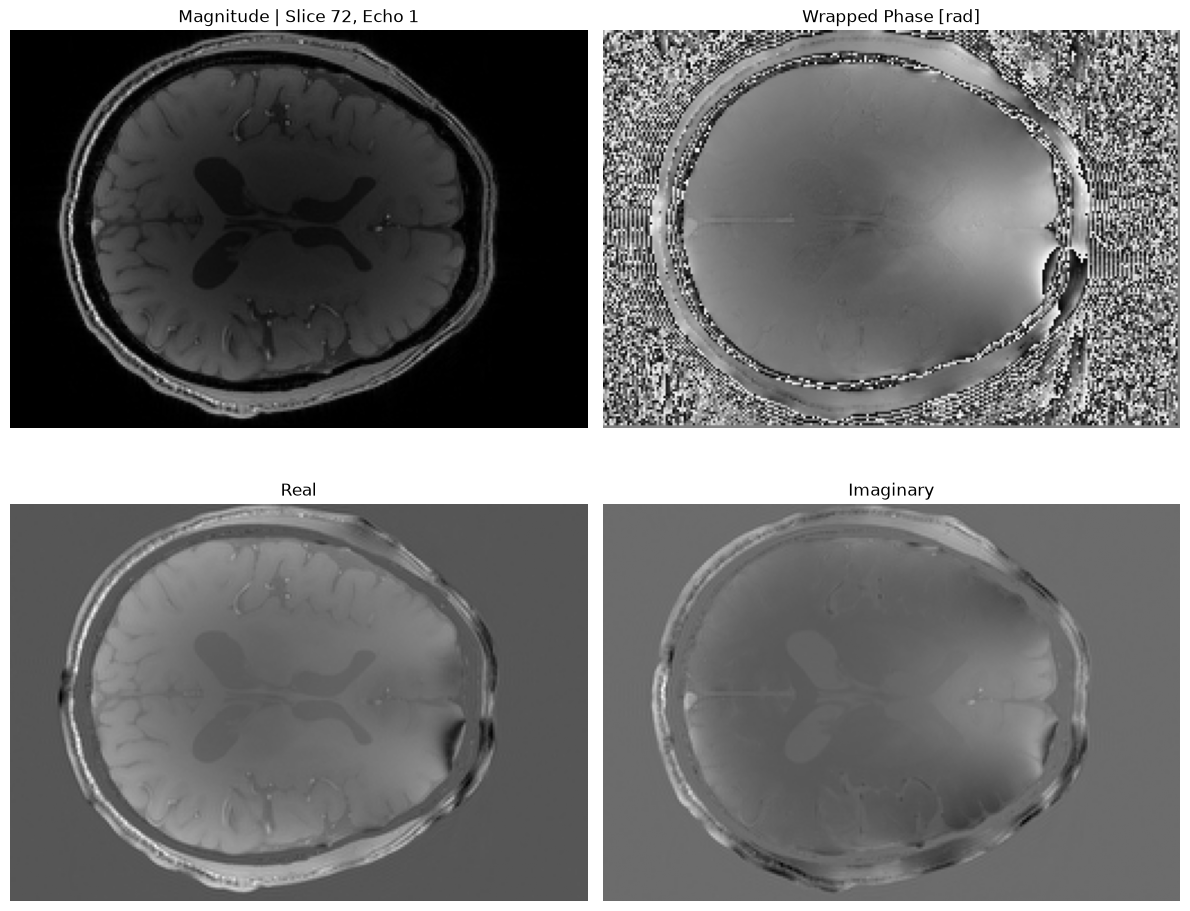

In [13]:
# ------------------------------------------------------------
# Complex 데이터 시각화
# ------------------------------------------------------------
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

ax[0, 0].imshow(magnitude_4d[:, :, slice_idx, echo_idx], cmap="gray")
ax[0, 0].set_title(f"Magnitude | Slice {slice_idx}, Echo {echo_idx + 1}")

ax[0, 1].imshow(phase_rad[:, :, slice_idx, echo_idx], cmap="gray")
ax[0, 1].set_title("Wrapped Phase [rad]")

ax[1, 0].imshow(real_4d[:, :, slice_idx, echo_idx], cmap="gray")
ax[1, 0].set_title("Real")

ax[1, 1].imshow(imag_4d[:, :, slice_idx, echo_idx], cmap="gray")
ax[1, 1].set_title("Imaginary")

for axis in ax.ravel():
    axis.axis("off")

plt.tight_layout()
plt.show()

### 5. 공식 Brain mask와 QSM mask 불러오기

공식 SEPIA 처리 결과에서 다음 두 mask를 불러온다.

#### Brain mask

- 파일: `mask_brain.nii.gz`
- Magnitude, Phase, Complex 분석 범위에 사용
- Noise sigma 계산에 사용
- 모든 noise level, seed, denoising 방법에 동일하게 고정

#### QSM mask

- 파일: `mask_QSM.nii.gz`
- Background field removal 이후 유효한 QSM 영역
- 최종 QSM 지표 계산에 사용
- 모든 방법에 동일하게 고정

두 mask의 shape과 affine이 원본 Magnitude와 일치하는지 확인한다.
QSM mask가 Brain mask 내부에 포함되어 있는지도 검증한다.

In [14]:
# ------------------------------------------------------------
# 공식 Brain mask와 QSM mask 불러오기
# ------------------------------------------------------------
brain_mask_img = nib.load(brain_mask_path)
qsm_mask_img = nib.load(qsm_mask_path)

brain_mask_raw = brain_mask_img.get_fdata(dtype=np.float32)
qsm_mask_raw = qsm_mask_img.get_fdata(dtype=np.float32)

# 0/1 값을 boolean으로 변환
brain_mask = brain_mask_raw > 0.5
qsm_mask = qsm_mask_raw > 0.5

print("Brain mask shape:", brain_mask.shape)
print("Brain mask dtype:", brain_mask.dtype)
print("Brain mask voxels:", np.sum(brain_mask))

print()

print("QSM mask shape:", qsm_mask.shape)
print("QSM mask dtype:", qsm_mask.dtype)
print("QSM mask voxels:", np.sum(qsm_mask))


# ------------------------------------------------------------
# Boolean 변환 후 원본 float mask 정리
# ------------------------------------------------------------
del brain_mask_raw
del qsm_mask_raw

Brain mask shape: (176, 256, 144)
Brain mask dtype: bool
Brain mask voxels: 1780588

QSM mask shape: (176, 256, 144)
QSM mask dtype: bool
QSM mask voxels: 1591599


In [15]:
# ------------------------------------------------------------
# Mask와 MRI 공간 일치 확인
# ------------------------------------------------------------
expected_shape = magnitude_4d.shape[:3]

if brain_mask.shape != expected_shape:
    raise ValueError(
        "Brain mask와 Magnitude의 shape이 다릅니다. "
        f"{brain_mask.shape} vs {expected_shape}"
    )

if qsm_mask.shape != expected_shape:
    raise ValueError(
        "QSM mask와 Magnitude의 shape이 다릅니다. "
        f"{qsm_mask.shape} vs {expected_shape}"
    )

if not np.allclose(
    brain_mask_img.affine,
    mag_affine,
):
    raise ValueError("Brain mask와 Magnitude의 affine이 다릅니다.")

if not np.allclose(
    qsm_mask_img.affine,
    mag_affine,
):
    raise ValueError("QSM mask와 Magnitude의 affine이 다릅니다.")

print("Mask shape/affine 검사 통과")

Mask shape/affine 검사 통과


In [16]:
# ------------------------------------------------------------
# QSM mask 포함 관계 확인
# ------------------------------------------------------------
qsm_outside_brain = qsm_mask & (~brain_mask)

n_qsm_outside_brain = np.sum(qsm_outside_brain)

print("Brain mask 밖의 QSM mask voxel:", n_qsm_outside_brain)

if n_qsm_outside_brain != 0:
    raise ValueError("QSM mask 일부가 Brain mask 밖에 있습니다.")

print("QSM mask가 Brain mask 내부에 있습니다.")


del qsm_outside_brain

Brain mask 밖의 QSM mask voxel: 0
QSM mask가 Brain mask 내부에 있습니다.


### 6. Brain mask와 QSM mask 시각화

중앙 axial slice에서 다음 영상을 비교한다.

1. 전체 Magnitude
2. 공식 Brain mask
3. Brain mask 내부 Magnitude
4. QSM mask 내부 Magnitude

Brain mask 결과에서는 두피와 두개골이 제외되어야 한다.
QSM mask는 Brain mask보다 조금 더 작은 영역을 포함할 수 있다.

한 slice만 확인하지 않고 위쪽, 중앙, 아래쪽 slice에서도 mask 경계를 확인한다.

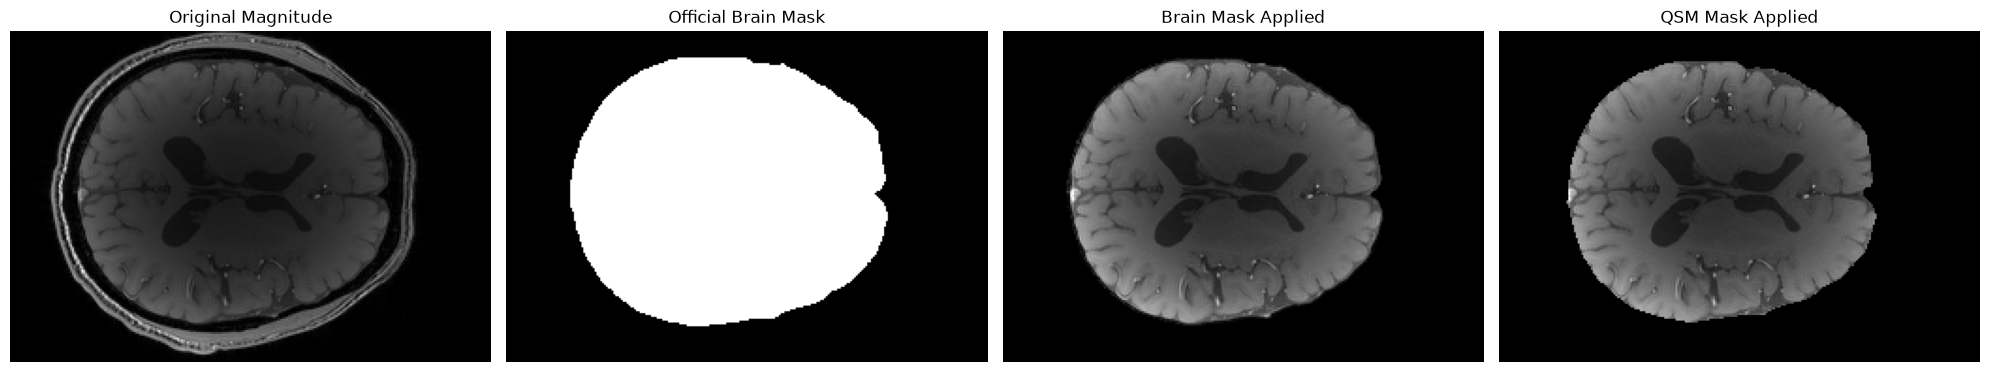

In [17]:
# ------------------------------------------------------------
# Mask 시각화
# ------------------------------------------------------------
magnitude_slice = magnitude_4d[:, :, slice_idx, echo_idx]
brain_mask_slice = brain_mask[:, :, slice_idx]
qsm_mask_slice = qsm_mask[:, :, slice_idx]

brain_only_magnitude = (
    magnitude_slice
    * brain_mask_slice
)

qsm_only_magnitude = (
    magnitude_slice
    * qsm_mask_slice
)

fig, ax = plt.subplots(1, 4, figsize=(20, 5))

ax[0].imshow(magnitude_slice, cmap="gray")
ax[0].set_title("Original Magnitude")

ax[1].imshow(brain_mask_slice, cmap="gray")
ax[1].set_title("Official Brain Mask")

ax[2].imshow(brain_only_magnitude, cmap="gray")
ax[2].set_title("Brain Mask Applied")

ax[3].imshow(qsm_only_magnitude, cmap="gray")
ax[3].set_title("QSM Mask Applied")

for axis in ax:
    axis.axis("off")

plt.tight_layout()
plt.show()

#### Mask 경계 overlay 확인

Magnitude 위에 Brain mask와 QSM mask를 반투명하게 표시하여 mask 경계가
실제 뇌 조직과 일치하는지 확인한다.

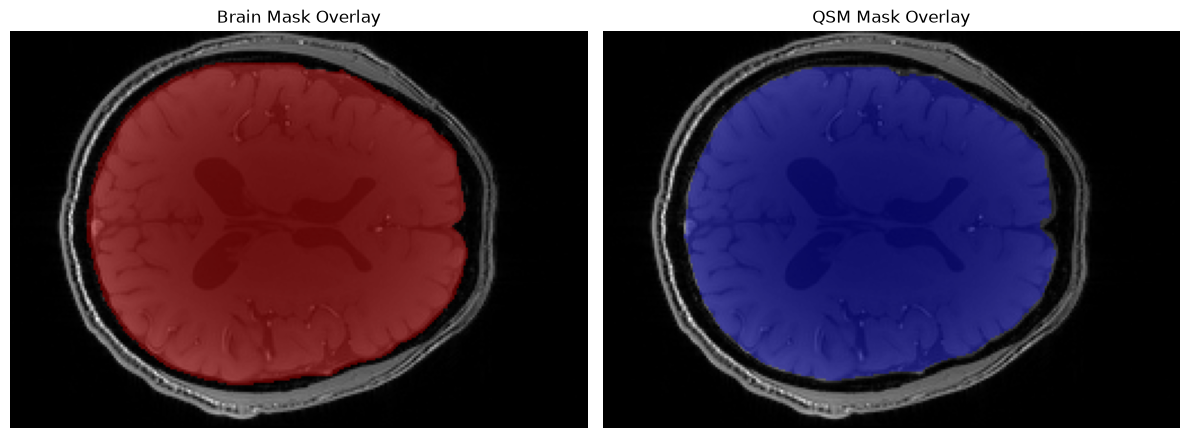

In [18]:
# ------------------------------------------------------------
# MRI 위에 mask를 반투명하게 표시
# ------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(magnitude_slice, cmap="gray")
ax[0].imshow(
    np.ma.masked_where(
        ~brain_mask_slice,
        brain_mask_slice,
    ),
    cmap="autumn",
    alpha=0.35,
)
ax[0].set_title("Brain Mask Overlay")

ax[1].imshow(magnitude_slice, cmap="gray")
ax[1].imshow(
    np.ma.masked_where(
        ~qsm_mask_slice,
        qsm_mask_slice,
    ),
    cmap="winter",
    alpha=0.35,
)
ax[1].set_title("QSM Mask Overlay")

for axis in ax:
    axis.axis("off")

plt.tight_layout()
plt.show()

### 7. Echo별 Brain mask 내부 평균 Magnitude 확인

공식 Brain mask 내부에서 각 echo의 평균 Magnitude를 계산한다.

일반적으로 Echo Time이 증가하면 T2* 감쇠로 인해 평균 Magnitude가 감소한다.
Echo별 평균 신호가 비정상적으로 증가하거나 특정 echo만 크게 다르면
Echo 순서와 데이터 로딩 과정을 다시 확인한다.

In [19]:
# ------------------------------------------------------------
# Echo별 Brain mask 내부 평균 Magnitude
# ------------------------------------------------------------
print("===== Mean magnitude inside brain mask =====")

mean_magnitude_by_echo = []

for echo_idx_loop in range(N_ECHOES):
    magnitude_echo = np.abs(
        meas_gre[
            ...,
            echo_idx_loop,
        ]
    )

    mean_signal = np.mean(
        magnitude_echo[brain_mask]
    )

    mean_magnitude_by_echo.append(
        mean_signal
    )

    print(
        f"Echo {echo_idx_loop + 1}: "
        f"{mean_signal:.4f}"
    )

===== Mean magnitude inside brain mask =====
Echo 1: 358.1047
Echo 2: 318.3268
Echo 3: 284.1363
Echo 4: 254.3431
Echo 5: 227.9906


### 8. Noise sigma 계산용 기준 신호 준비

인공 잡음의 표준편차는 Brain mask 내부 Echo 1 평균 Magnitude를 기준으로 정의한다.

$$
\sigma
=
\overline{M}_{\mathrm{brain,echo1}}
\times
\frac{\mathrm{noise\ level}}{100}
$$

이 노트북에서는 기준 평균값까지만 계산한다.
실제 잡음 생성은 다음 단계의 노트북에서 수행한다.

In [20]:
# ------------------------------------------------------------
# Noise sigma 계산용 기준 신호
# ------------------------------------------------------------
reference_echo_idx = 0

reference_magnitude = np.abs(
    meas_gre[
        ...,
        reference_echo_idx,
    ]
)

mean_brain_magnitude_echo1 = np.mean(
    reference_magnitude[brain_mask]
)

print("Reference echo:", reference_echo_idx + 1)
print("Mean magnitude inside brain mask:", mean_brain_magnitude_echo1)

Reference echo: 1
Mean magnitude inside brain mask: 358.10474


In [21]:
# ------------------------------------------------------------
# Dataset summary
# ------------------------------------------------------------
echo_times_ms = np.asarray(echo_times, dtype=np.float64) * 1000.0

if echo_times_ms.shape != (N_ECHOES,):
    raise ValueError(
        "EchoTime 개수가 예상과 다릅니다. "
        f"shape={echo_times_ms.shape}"
    )

print("===== Dataset summary =====")

print("Spatial shape       :", meas_gre.shape[:3])
print("Number of echoes    :", meas_gre.shape[-1])
print("Complex shape       :", meas_gre.shape)
print("Complex dtype       :", meas_gre.dtype)

print("Echo times [ms]     :", echo_times * 1000)
print("Field strength [T]  :", field_strength)
print("Brain mask voxels   :", np.sum(brain_mask))
print("QSM mask voxels     :", np.sum(qsm_mask))
print("Display slice       :", slice_idx)

===== Dataset summary =====
Spatial shape       : (176, 256, 144)
Number of echoes    : 5
Complex shape       : (176, 256, 144, 5)
Complex dtype       : complex64
Echo times [ms]     : [ 5.25 11.08 16.91 22.74 28.57]
Field strength [T]  : 3
Brain mask voxels   : 1780588
QSM mask voxels     : 1591599
Display slice       : 72


### 9. 선택 사항: 전처리 결과 저장

`SAVE_PROCESSED = True`로 설정하면 다음 데이터를 `.npz` 파일로 저장한다.

- `meas_gre`: 4D Complex GRE
- `brain_mask`: MRI/MP-PCA 평가용 Brain mask
- `qsm_mask`: 최종 QSM 평가용 QSM mask
- `echo_times`: EchoTime, 단위 second
- `field_strength`: Magnetic field strength, 단위 Tesla
- `affine`: 원본 NIfTI 공간정보

파일 크기가 클 수 있으므로 데이터 검증이 끝나기 전에는
`SAVE_PROCESSED = False`로 유지한다.

In [24]:
# ------------------------------------------------------------
# 선택 사항: 전처리 결과 저장
# ------------------------------------------------------------
SAVE_PROCESSED = True

if SAVE_PROCESSED:
    output_dir = os.path.join(
        PROJECT_ROOT,
        "data",
        "processed",
    )

    os.makedirs(output_dir, exist_ok=True)

    output_path = os.path.join(
        output_dir,
        (
            "qsm_consensus_siemens_"
            "monopolar_complex.npz"
        ),
    )

    np.savez_compressed(
        output_path,
        meas_gre=meas_gre,
        brain_mask=brain_mask,
        qsm_mask=qsm_mask,
        echo_times=np.asarray(echo_times, dtype=np.float64),
        field_strength=(
            np.nan
            if field_strength is None
            else float(field_strength)
        ),
        affine=mag_affine,
    )

    print("Saved:")
    print(output_path)

else:
    print(
        "SAVE_PROCESSED=False: "
        "저장하지 않았습니다."
    )

Saved:
C:\Users\lilly\OneDrive - 한국외국어대학교\바탕 화면\졸업프로젝트\01_public_qsm\data\processed\qsm_consensus_siemens_monopolar_complex.npz


In [25]:
# ------------------------------------------------------------
# 저장 결과 확인
# ------------------------------------------------------------
if not os.path.exists(output_path):
    raise FileNotFoundError(f"저장된 파일을 찾을 수 없습니다:\n{output_path}")

file_size_mb = (os.path.getsize(output_path) / (1024 ** 2))

print("Saved file:")
print(output_path)

print(f"File size: {file_size_mb:.2f} MB")

with np.load(output_path) as saved:
    print("\nSaved variables:")
    print(saved.files)

    print("\nmeas_gre:", saved["meas_gre"].shape, saved["meas_gre"].dtype)
    print("brain_mask:", saved["brain_mask"].shape, saved["brain_mask"].dtype)
    print("qsm_mask:", saved["qsm_mask"].shape, saved["qsm_mask"].dtype)
    print("echo_times:", saved["echo_times"])
    print("field_strength:", saved["field_strength"])
    print("affine shape:", saved["affine"].shape)

Saved file:
C:\Users\lilly\OneDrive - 한국외국어대학교\바탕 화면\졸업프로젝트\01_public_qsm\data\processed\qsm_consensus_siemens_monopolar_complex.npz
File size: 217.57 MB

Saved variables:
['meas_gre', 'brain_mask', 'qsm_mask', 'echo_times', 'field_strength', 'affine']

meas_gre: (176, 256, 144, 5) complex64
brain_mask: (176, 256, 144) bool
qsm_mask: (176, 256, 144) bool
echo_times: [0.00525 0.01108 0.01691 0.02274 0.02857]
field_strength: 3.0
affine shape: (4, 4)
